In [6]:
import pandas as pd
import numpy as np
import sklearn

In [4]:
file_path = r"dataset.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (235795, 56)


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


In [5]:
print("Columns:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


Columns:
['FILENAME', 'URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef', 'label']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 235795 entr

In [ ]:
# Check the distribution of target labels
print("Label distribution:")
print(df["label"].value_counts())

print("\nLabel percentages:")
print((df["label"].value_counts(normalize=True) * 100).round(2))          #0 - phishing, 1 - legitimate

print("\nMissing values:")
print(df[["URL", "label"]].isnull().sum())

Label distribution:
label
1    134850
0    100945
Name: count, dtype: int64

Label percentages:
label
1    57.19
0    42.81
Name: proportion, dtype: float64

Missing values:
URL      0
label    0
dtype: int64


In [8]:
# Keep only the columns needed for URL-based detection
data = df[["URL", "label"]].copy()

# Remove rows with missing URLs or labels
data = data.dropna(subset=["URL", "label"])

# Convert URLs to strings and labels to integers
data["URL"] = data["URL"].astype(str).str.strip()
data["label"] = data["label"].astype(int)

# Remove empty URLs
data = data[data["URL"] != ""]

# Remove duplicate URLs
data = data.drop_duplicates(subset=["URL"]).reset_index(drop=True)

print("Clean dataset shape:", data.shape)
print("\nLabel distribution after cleaning:")
print(data["label"].value_counts())

display(data.head())

Clean dataset shape: (235370, 2)

Label distribution after cleaning:
label
1    134850
0    100520
Name: count, dtype: int64


,URL,label
0,https://www.southbankmosaics.com,1
1,https://www.uni-mainz.de,1
2,https://www.voicefmradio.co.uk,1
3,https://www.sfnmjournal.com,1
4,https://www.rewildingargentina.org,1


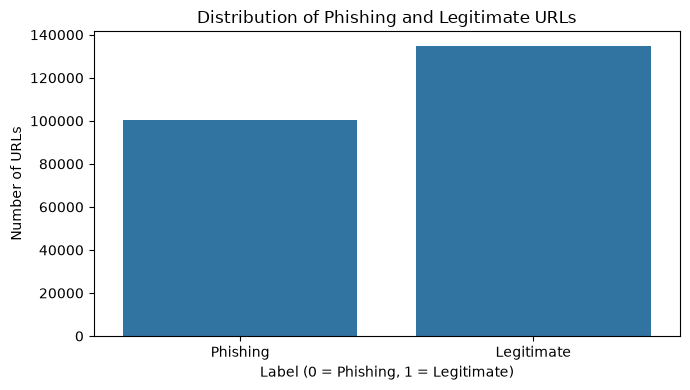

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4))

sns.countplot(data=data,x="label")

plt.title("Distribution of Phishing and Legitimate URLs")
plt.xlabel("Label (0 = Phishing, 1 = Legitimate)")
plt.ylabel("Number of URLs")
plt.xticks([0, 1], ["Phishing", "Legitimate"])
plt.tight_layout()
plt.show()

In [10]:
import re
import math
import ipaddress

from collections import Counter
from urllib.parse import urlparse


SUSPICIOUS_WORDS = [
    "login", "verify", "account", "update", "secure",
    "banking", "signin", "password", "confirm", "wallet",
    "payment", "recover", "authenticate", "webscr"
]


def extract_url_features(url):
    url = str(url).strip()

    # Allow URLs without an explicitly provided scheme
    parsed = urlparse(url if "://" in url else "//" + url)

    hostname = parsed.hostname or ""
    path = parsed.path or ""
    query = parsed.query or ""

    # Count IP-address hosts
    is_ip_address = 0

    try:
        ipaddress.ip_address(hostname)
        is_ip_address = 1
    except ValueError:
        pass

    # Count characters and symbols
    digit_count = sum(char.isdigit() for char in url)


    special_chars = sum(not char.isalnum() for char in url)

    hyphen_count = url.count("-")
    dot_count = hostname.count(".")

    # Count subdomains approximately
    subdomain_count = max(dot_count - 1, 0)

    # Estimate character entropy
    if url:
        probabilities = [count / len(url) for count in Counter(url).values()]
        entropy = -sum(p * math.log2(p) for p in probabilities)
    else:
        entropy = 0.0

    # Count suspicious terms
    suspicious_word_count = sum(len(re.findall(r"[a-z0-9]+", word))for word in [])
    suspicious_word_count = sum(url.lower().count(word)for word in SUSPICIOUS_WORDS)
    # Detect percent-encoded characters
    percent_encoding_count = len(re.findall(r"%[0-9a-fA-F]{2}", url))

    # Extract query parameter count
    query_parameter_count = (len([item for item in query.split("&") if item])if query else 0)

    return {
        "url_length": len(url),
        "hostname_length": len(hostname),
        "path_length": len(path),
        "query_length": len(query),
        "dot_count": dot_count,
        "subdomain_count": subdomain_count,
        "digit_count": digit_count,
        "special_char_count": special_chars,
        "hyphen_count": hyphen_count,
        "at_symbol": int("@" in url),
        "https_scheme": int(parsed.scheme.lower() == "https"),
        "ip_address_host": is_ip_address,
        "percent_encoding_count": percent_encoding_count,
        "query_parameter_count": query_parameter_count,
        "suspicious_word_count": suspicious_word_count,
        "entropy": entropy,
        "double_slash_in_path": int("//" in path),
    }


# Test the feature extractor
test_url = "https://secure-example.com/login?account=verify"

test_features = extract_url_features(test_url)

print("Test URL:", test_url)
display(pd.DataFrame([test_features]))

Test URL: https://secure-example.com/login?account=verify


,url_length,hostname_length,path_length,query_length,dot_count,subdomain_count,digit_count,special_char_count,hyphen_count,at_symbol,https_scheme,ip_address_host,percent_encoding_count,query_parameter_count,suspicious_word_count,entropy,double_slash_in_path
0,47,18,6,14,1,0,0,8,1,0,1,0,0,1,4,4.45088,0


In [11]:
# Extract numerical features from every URL
feature_records = [
    extract_url_features(url)
    for url in data["URL"]
]

X = pd.DataFrame(feature_records)
y = data["label"].copy()

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

display(X.head())

Feature matrix shape: (235370, 17)
Target vector shape: (235370,)


,url_length,hostname_length,path_length,query_length,dot_count,subdomain_count,digit_count,special_char_count,hyphen_count,at_symbol,https_scheme,ip_address_host,percent_encoding_count,query_parameter_count,suspicious_word_count,entropy,double_slash_in_path
0,32,24,0,0,2,1,0,5,0,0,1,0,0,0,0,3.929229,0
1,24,16,0,0,2,1,0,6,1,0,1,0,0,0,0,3.970176,0
2,30,22,0,0,3,2,0,6,0,0,1,0,0,0,0,4.164735,0
3,27,19,0,0,2,1,0,5,0,0,1,0,0,0,0,4.060262,0
4,34,26,0,0,2,1,0,5,0,0,1,0,0,0,0,3.917626,0


In [12]:
print("Missing feature values:", X.isnull().sum().sum())
print("Infinite feature values:", np.isinf(X.to_numpy()).sum())

print("\nTarget labels:")
print(y.value_counts().sort_index())

print("\nNumber of features:", X.shape[1])

Missing feature values: 0
Infinite feature values: 0

Target labels:
label
0    100520
1    134850
Name: count, dtype: int64

Number of features: 17


TRAIN TEST SPLIT

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 188296
Testing samples: 47074


COMPARE PERFORMANCE OF 2 MODELS
LOGISTIC REGRESSION vs LINEAR SVM

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Linear SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearSVC(
            class_weight="balanced",
            random_state=42,
            max_iter=5000
        ))
    ])
}

print("Models created successfully!")

Models created successfully!


In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

results = []
trained_models = {}

for name, model in models.items():
    print(f"\nTraining {name}...")

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Phishing Precision": precision_score(y_test, y_pred, pos_label=0, zero_division=0),
        "Phishing Recall": recall_score(y_test, y_pred, pos_label=0, zero_division=0),
        "Phishing F1": f1_score(y_test, y_pred, pos_label=0, zero_division=0)}

    results.append(metrics)
    trained_models[name] = model

    print(f"\n{name} classification report:")
    print(classification_report(y_test,y_pred,labels=[0, 1],target_names=["Phishing", "Legitimate"],zero_division=0))

results_df = pd.DataFrame(results).sort_values(by="Phishing F1",ascending=False).reset_index(drop=True)

display(results_df)


Training Logistic Regression...

Logistic Regression classification report:
              precision    recall  f1-score   support

    Phishing       1.00      0.98      0.99     20104
  Legitimate       0.99      1.00      0.99     26970

    accuracy                           0.99     47074
   macro avg       0.99      0.99      0.99     47074
weighted avg       0.99      0.99      0.99     47074


Training Linear SVM...

Linear SVM classification report:
              precision    recall  f1-score   support

    Phishing       1.00      0.98      0.99     20104
  Legitimate       0.99      1.00      0.99     26970

    accuracy                           0.99     47074
   macro avg       0.99      0.99      0.99     47074
weighted avg       0.99      0.99      0.99     47074



,Model,Accuracy,Phishing Precision,Phishing Recall,Phishing F1
0,Logistic Regression,0.993223,0.999243,0.984879,0.992009
1,Linear SVM,0.992799,0.999899,0.983237,0.991498


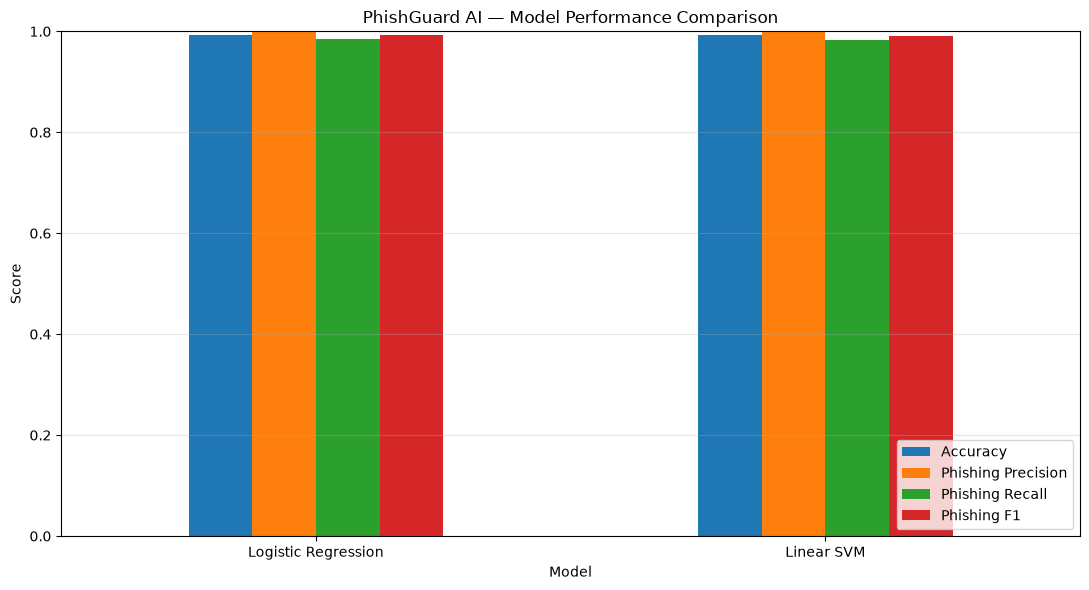

In [20]:
metrics_to_plot = ["Accuracy","Phishing Precision","Phishing Recall","Phishing F1"]

results_df.set_index("Model")[metrics_to_plot].plot(kind="bar",figsize=(11, 6),ylim=(0, 1),rot=0)

plt.title("PhishGuard AI — Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Best model by phishing F1-score: Logistic Regression


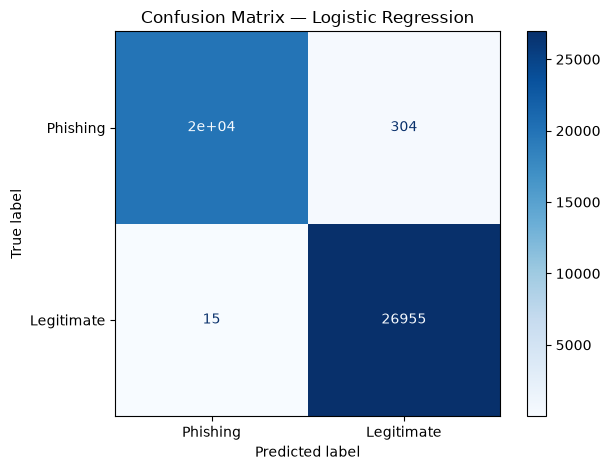

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

best_predictions = best_model.predict(X_test)

print("Best model by phishing F1-score:", best_model_name)

ConfusionMatrixDisplay.from_predictions(y_test,best_predictions,labels=[0, 1],display_labels=["Phishing", "Legitimate"],cmap="Blues")

plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

CROSS VALIDATION

5 Fold stratified cross validation

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Select the best model from the previous comparison
cv_model = trained_models[best_model_name]

# Create 5-fold stratified cross-validation
skf = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

# Score phishing as the positive class (label 0)
scoring = {
    "accuracy": "accuracy",
    "phishing_precision": "precision",
    "phishing_recall": "recall",
    "phishing_f1": "f1"
}

# Use custom scorers so phishing (label 0) is evaluated correctly
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

scoring["phishing_precision"] = make_scorer(precision_score, pos_label=0, zero_division=0)
scoring["phishing_recall"] = make_scorer(recall_score, pos_label=0, zero_division=0)
scoring["phishing_f1"] = make_scorer(f1_score, pos_label=0, zero_division=0)

cv_results = cross_validate(cv_model,X_train,y_train,cv=skf,scoring=scoring,n_jobs=-1,return_train_score=True)

print("Cross-validation results:\n")

for metric in scoring:
    scores = cv_results[f"test_{metric}"]
    print(f"{metric}: {scores.mean():.4f} "
        f"+/- {scores.std():.4f}")

Cross-validation results:

accuracy: 0.9933 +/- 0.0002
phishing_precision: 0.9991 +/- 0.0002
phishing_recall: 0.9852 +/- 0.0004
phishing_f1: 0.9921 +/- 0.0003


HYPERPARAMETER TUNING

Grid Search CV

In [28]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, f1_score

logistic_pipeline = models["Logistic Regression"]

param_grid = {"model__C": [0.01, 0.1, 1, 10]}
phishing_f1_scorer = make_scorer(f1_score,pos_label=0,zero_division=0)

grid_search = GridSearchCV(estimator=logistic_pipeline,param_grid=param_grid,scoring=phishing_f1_scorer,
cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=42),n_jobs=-1,verbose=1)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation phishing F1:", round(grid_search.best_score_, 4))

tuned_model = grid_search.best_estimator_

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best parameters: {'model__C': 10}
Best cross-validation phishing F1: 0.9922


EVALUATION

Final model: Tuned Logistic Regression
Accuracy: 0.9934
Phishing precision: 0.9992
Phishing recall: 0.9852
Phishing F1: 0.9922

Detailed classification report:
              precision    recall  f1-score   support

    Phishing       1.00      0.99      0.99     20104
  Legitimate       0.99      1.00      0.99     26970

    accuracy                           0.99     47074
   macro avg       0.99      0.99      0.99     47074
weighted avg       0.99      0.99      0.99     47074



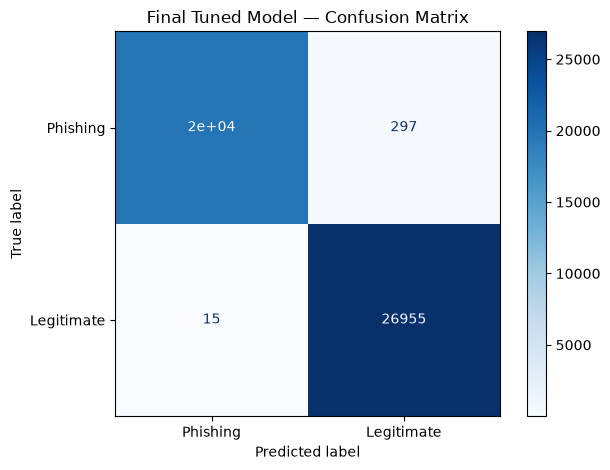

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

final_predictions = tuned_model.predict(X_test)

print("Final model: Tuned Logistic Regression")
print("Accuracy:", round(accuracy_score(y_test, final_predictions), 4))
print("Phishing precision:", round(precision_score(y_test, final_predictions, pos_label=0, zero_division=0), 4))
print("Phishing recall:", round(recall_score(y_test, final_predictions, pos_label=0, zero_division=0), 4))
print("Phishing F1:", round(f1_score(y_test, final_predictions, pos_label=0, zero_division=0), 4))

print("\nDetailed classification report:")
print(classification_report(y_test,final_predictions,labels=[0, 1],target_names=["Phishing", "Legitimate"],zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test,final_predictions,labels=[0, 1],display_labels=["Phishing", "Legitimate"],cmap="Blues")

plt.title("Final Tuned Model — Confusion Matrix")
plt.tight_layout()
plt.show()

In [24]:
import joblib
import json

model_path = "phishguard_model.joblib"
features_path = "phishguard_features.json"

joblib.dump(tuned_model, model_path)

with open(features_path, "w", encoding="utf-8") as file:
    json.dump(list(X.columns), file, indent=4)

print("Model saved to:", model_path)
print("Feature list saved to:", features_path)

Model saved to: phishguard_model.joblib
Feature list saved to: phishguard_features.json


-----------------------------------------------------------------------------------------------------------------------------------------------

PREDICTOR FUNCTION()

In [29]:
def predict_url(url):
    url = str(url).strip()

    if not url:
        return {
            "url": url,
            "prediction": "Invalid input",
            "message": "Please enter a URL."
        }

    # Extract the same features used during training
    features = extract_url_features(url)

    # Convert the features into a DataFrame
    input_df = pd.DataFrame([features], columns=X.columns)

    # Predict the label
    prediction = int(tuned_model.predict(input_df)[0])

    if prediction == 0:
        result = "Potentially Phishing"
        message = "Warning: this URL has characteristics associated with phishing."
    else:
        result = "Potentially Legitimate"
        message = "This URL appears more consistent with legitimate URLs in the training data."


    return {"url": url,"prediction": result,"message": message}


# Test with example URLs
test_urls = [
    "https://www.google.com",
    "http://192.168.1.10/login",
    "https://secure-example.com/verify-account"
]

for url in test_urls:
    result = predict_url(url)
    print("\nURL:", result["url"])
    print("Prediction:", result["prediction"])
    print("Assessment:", result["message"])


URL: https://www.google.com
Prediction: Potentially Legitimate
Assessment: This URL appears more consistent with legitimate URLs in the training data.

URL: http://192.168.1.10/login
Prediction: Potentially Phishing
Assessment: Warning: this URL has characteristics associated with phishing.

URL: https://secure-example.com/verify-account
Prediction: Potentially Phishing
Assessment: Warning: this URL has characteristics associated with phishing.


In [26]:
test_urls = [
    "https://www.google.com",
    "https://www.wikipedia.org",
    "http://192.168.1.10/login",
    "https://secure-example.com/verify-account",
    "http://paypal-login-example.com/account/verify"
]

batch_results = []

for url in test_urls:
    result = predict_url(url)
    batch_results.append(result)

batch_df = pd.DataFrame(batch_results)

display(batch_df)

,url,prediction,message
0,https://www.google.com,Potentially Legitimate,This URL appears more consistent with legitima...
1,https://www.wikipedia.org,Potentially Legitimate,This URL appears more consistent with legitima...
2,http://192.168.1.10/login,Potentially Phishing,Warning: this URL has characteristics associat...
3,https://secure-example.com/verify-account,Potentially Phishing,Warning: this URL has characteristics associat...
4,http://paypal-login-example.com/account/verify,Potentially Phishing,Warning: this URL has characteristics associat...


In [27]:
batch_df.to_csv("phishguard_test_predictions.csv", index=False)

print("Predictions saved to phishguard_test_predictions.csv")

Predictions saved to phishguard_test_predictions.csv
